---
title: "First Law, Heat, Work and Heat Capacity — Level 2"
short_title: "02 First Law & Heat Capacity"
numbering:
  heading_2: true
  equation: true
---

# First Law, Heat, Work and Heat Capacity

:::{seealso} Math for this topic
- [T-M3: Exact differentials and thermodynamic calculus](../math/03-thermodynamic-calculus.ipynb)
- [M3: Multivariable calculus](../../level2-book/math/03-multivariable-calculus.ipynb)
:::

:::{tip} Where this sits on the ladder
| Level | Text | What you do |
|---|---|---|
| 1 | Tipler & Mosca, ch. 18–19 | Q, W and ΔU for ideal-gas processes |
| **2** | **Schroeder, ch. 1** | **Heat capacities of solids and gases, enthalpy, adiabatic processes** |
| 3 | Pathria, ch. 1 | Thermodynamic potentials and Legendre transforms from the ensemble |

The new skill at this level: treating heat and work as path-dependent transfers and energy as a state function, and choosing the right state function (U or H) for the process

Math for this topic: T-M3 (exact differentials) and mechanics M3 (partial derivatives).
:::

Workbook example ladder: isothermal versus adiabatic expansion → enthalpy in a constant-pressure process → potentials as derivatives of ln Z. Exercises have separate hint and answer dropdowns.

::::{admonition} Pre-test: can you skip this notebook?
:class: dropdown

Work these without looking at the notes. Each problem names the section it tests. If **every part** is right, skip ahead to [Entropy and the Second Law](03-entropy-second-law.ipynb). If you miss a part, study just the section it names and try that problem again.

1. **Energy, Heat and Work**

   (a) One mole of ideal gas is compressed slowly and isothermally at 300 K from 20 L to 10 L. Find the work done on the gas and the heat it exchanges.

   (b) Which of $U$, $Q$ and $W$ are state functions?

2. **Isothermal and Adiabatic Processes**

   One mole of a monatomic ideal gas at 400 K expands adiabatically and quasistatically to twice its volume.

   (a) Find the final temperature and the ratio $P_f/P_i$.

   (b) Find the work done by the gas.

3. **Heat Capacity**

   (a) For an ideal gas, what is $C_P - C_V$?

   (b) How much heat warms 2 mol of a diatomic gas from 300 K to 350 K at constant pressure? At constant volume?

   (c) How much heat melts 0.10 kg of ice at 0 °C ($L = 334$ kJ/kg)?

4. **Enthalpy**

   (a) Why is $\Delta H$, not $\Delta U$, the heat absorbed at constant pressure?

   (b) Boiling 1 mol of water at 373 K absorbs 40.7 kJ. Estimate $\Delta U$, treating the vapor as an ideal gas and neglecting the liquid's volume.

:::{dropdown} Answers
1. (a) $W = NkT\ln(V_i/V_f) = RT\ln2 \approx 1.73$ kJ on the gas, and $Q = -1.73$ kJ (heat flows out).

   (b) Only $U$.

2. (a) $T_f = 400\times2^{-2/3} \approx 252$ K, and $P_f/P_i = 2^{-5/3} \approx 0.31$.

   (b) $-\Delta U = \tfrac32R(400 - 252) \approx 1.8$ kJ.

3. (a) $Nk$ (that is, $nR$).

   (b) At constant pressure, $2\times\tfrac72R\times50 \approx 2.9$ kJ. At constant volume, $2\times\tfrac52R\times50 \approx 2.1$ kJ.

   (c) $33.4$ kJ.

4. (a) At constant $P$, the first law gives $Q = \Delta U + P\Delta V = \Delta(U + PV) = \Delta H$.

   (b) $\Delta U = \Delta H - P\Delta V \approx 40.7 - RT \approx 40.7 - 3.1 = 37.6$ kJ.
:::
::::

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import Math, display
from scipy.integrate import solve_ivp, quad
from scipy.optimize import brentq

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
k_B = 1.380649e-23     # J/K
N_A = 6.02214e23       # 1/mol
R_gas = k_B * N_A      # J/(mol K)
h = 6.62607e-34        # J s
hbar = h / (2 * np.pi)
eV = 1.602177e-19      # J
np.seterr(over="ignore", divide="ignore", invalid="ignore")   # plots hit inf at the edges; harmless here

{'divide': 'warn', 'over': 'warn', 'under': 'ignore', 'invalid': 'warn'}

## Energy, Heat and Work

The **first law** is energy conservation with the bookkeeping split by mechanism:

$$
\Delta U = Q + W .
$$ (eq-first-law)

- $Q$ is **heat**: energy that crosses the boundary *because of a temperature difference*.
- $W$ is **work**: energy that crosses by any other means (a moving piston, a stirring paddle, a current through a resistor).
- $U$ is the **internal energy**, the total microscopic energy inside.

This book counts both $Q$ and $W$ as positive when energy goes *into* the system (Schroeder's convention). Many engineering texts use $\Delta U = Q - W$ with $W$ done *by* the system; the physics is the same.

The key asymmetry: $U$ is a **state function** (it depends only on the current state), while $Q$ and $W$ describe *processes*. "The heat in a gas" means nothing; "the heat added during this process" does. In T-M3 language, $dU$ is exact while $\delta Q$ and $\delta W$ are not.

### Compression work

A piston of area $A$ pushed in by $dx$ against pressure $P$ does work $PA\,dx = -P\,dV$ on the gas. If the process is **quasistatic** (slow enough that the gas stays uniform with a well-defined pressure throughout),

$$
W = -\int_{V_i}^{V_f}P\,dV .
$$ (eq-compression-work)

On a $PV$ diagram, $|W|$ is the area under the path, and different paths between the same endpoints enclose different areas.

## Isothermal and Adiabatic Processes

**Isothermal** ($T$ constant, gas in contact with a reservoir). For an ideal gas $U$ depends only on $T$, so $\Delta U = 0$ and $Q = -W$:

$$
W = -NkT\ln\frac{V_f}{V_i},\qquad Q = NkT\ln\frac{V_f}{V_i} .
$$ (eq-isothermal-work)

**Adiabatic** ($Q = 0$, insulated or too fast for heat to flow). Now all the work goes into $U$, so compressing the gas heats it.

:::{prf:theorem} The adiabat of an ideal gas
:label: thm-adiabat

For a quasistatic adiabatic process of an ideal gas with $f$ degrees of freedom,

$$
VT^{f/2} = \text{const},\qquad PV^\gamma = \text{const},\qquad \gamma = \frac{f + 2}{f} = \frac{C_P}{C_V} .
$$ (eq-adiabat)
:::

:::{prf:proof}
:class: dropdown

With $Q = 0$, $dU = -P\,dV$. Using $U = \tfrac f2NkT$ and $P = NkT/V$:

$$
\frac f2Nk\,dT = -\frac{NkT}{V}dV\quad\Rightarrow\quad\frac f2\frac{dT}{T} = -\frac{dV}{V}\quad\Rightarrow\quad\frac f2\ln T + \ln V = \text{const} .
$$

So $VT^{f/2}$ is constant. Substituting $T\propto PV$ gives $V^{(f+2)/2}P^{f/2} = $ const, which is $PV^\gamma = $ const after raising to the power $2/f$.
:::

In [2]:
# The same adiabat from the differential equation dU = -P dV, solved by SymPy
Vs = sp.symbols("V", positive=True)
f_, N_, k_ = sp.symbols("f N k", positive=True)
Tf = sp.Function("T")
ode = sp.Eq(f_ / 2 * N_ * k_ * Tf(Vs).diff(Vs), -N_ * k_ * Tf(Vs) / Vs)
sol = sp.dsolve(ode)
display(Math(sp.latex(sol)))

<IPython.core.display.Math object>

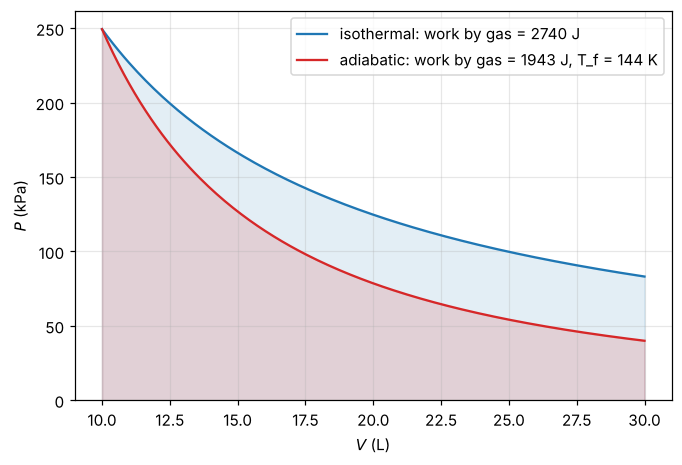

In [3]:
#| label: fig-isotherm-adiabat
#| caption: "Expansion of 1 mol of monatomic gas from 10 L at 300 K to 30 L. The isotherm (blue) keeps T fixed by drawing heat from a reservoir; the adiabat (red, PV^(5/3) constant) draws none, so the gas cools to 144 K and does less work. Shaded areas are the work done by the gas."
R = R_gas; Vi, Vf, Ti = 0.010, 0.030, 300.0
V = np.linspace(Vi, Vf, 200)
P_iso = R * Ti / V
gam = 5 / 3
P_ad = (R * Ti / Vi) * (Vi / V)**gam
fig, ax = plt.subplots()
ax.plot(V * 1e3, P_iso / 1e3, color="tab:blue", label=f"isothermal: work by gas = {R * Ti * np.log(Vf / Vi):.0f} J")
ax.fill_between(V * 1e3, P_iso / 1e3, alpha=0.12, color="tab:blue")
Tf_ad = Ti * (Vi / Vf)**(gam - 1)
ax.plot(V * 1e3, P_ad / 1e3, color="tab:red", label=f"adiabatic: work by gas = {1.5 * R * (Ti - Tf_ad):.0f} J, T_f = {Tf_ad:.0f} K")
ax.fill_between(V * 1e3, P_ad / 1e3, alpha=0.15, color="tab:red")
ax.set_xlabel("$V$ (L)"); ax.set_ylabel("$P$ (kPa)"); ax.set_ylim(0); ax.legend(); plt.show()

The adiabat is steeper than the isotherm because the gas cools as it expands, so its pressure falls for two reasons at once.

::::{prf:example} Level 1 rung: ignition in a diesel engine
:label: ex-diesel-ignition

A diesel engine compresses air ($\gamma = 1.4$) by a factor of 20, quickly enough to be adiabatic. If the air starts at 300 K, how hot does it get?

:::{dropdown} Solution
From $VT^{f/2}$ = const with $f = 5$: $T_f = T_i(V_i/V_f)^{2/f} = 300\times20^{0.4} = 994$ K, about 720 °C. That is above the autoignition temperature of diesel fuel (roughly 500 K), so the fuel sprayed into the cylinder burns with no spark plug.
:::
::::

## Heat Capacity

The heat capacity is the heat per degree of temperature rise, $C = Q/\Delta T$. Because $Q$ depends on the process, so does $C$. The two standard choices:

$$
C_V = \left(\frac{\partial U}{\partial T}\right)_V ,\qquad
C_P = \left(\frac{\partial U}{\partial T}\right)_P + P\left(\frac{\partial V}{\partial T}\right)_P .
$$ (eq-cv-cp)

At constant pressure the system expands while heating and pushes the surroundings back, so some of the heat leaves as work and $C_P > C_V$. For an ideal gas $(\partial U/\partial T)_P = (\partial U/\partial T)_V$ (since $U$ depends only on $T$) and $P(\partial V/\partial T)_P = Nk$, so

$$
C_P - C_V = Nk .
$$ (eq-mayer)

For solids and liquids the expansion is tiny and $C_P\approx C_V$ to a few percent.

**Specific heats of solids.** Equipartition gives $3k$ per atom, $3R = 24.9$ J/(mol·K), the Dulong–Petit value, and most elements are close at room temperature. Diamond is the famous exception (about 6 J/(mol·K)): its stiff bonds put the vibrational level spacing above $kT$, and the modes freeze out (thermo topic 6 and the Einstein model in topic 3).

**Latent heat.** During a phase change, heat goes in with no temperature change at all, so $C$ is infinite. The **latent heat** $L$ is the heat per unit mass to complete the transformation: 334 J/g to melt ice, 2260 J/g to boil water at 1 atm.

## Enthalpy

At constant pressure, which is how most chemistry and biology happens, the heat absorbed is not $\Delta U$ but $\Delta U + P\Delta V$. That combination gets its own name.

:::{prf:definition} Enthalpy
:label: def-enthalpy

$$
H = U + PV .
$$ (eq-enthalpy)

At constant pressure with only compression work, $\Delta H = Q$, and $C_P = (\partial H/\partial T)_P$.
:::

Think of $H$ as the energy you would need to create the system out of nothing *and* push the atmosphere out of the way to make room for it. Tables list enthalpies of formation and reaction because the experiments are done open to the air.

::::{prf:example} Level 2 rung: boiling water
:label: ex-boiling-enthalpy

Boiling 1.00 mol (18.0 g) of water at 100 °C and 1 atm absorbs $\Delta H = 40.7$ kJ. How much of that is the increase in internal energy, and how much is work pushing back the atmosphere?

:::{dropdown} Solution
The vapor occupies $V = RT/P = (8.314)(373)/(1.013\times10^5) = 30.6$ L (the liquid's 0.018 L is negligible). The work done on the atmosphere is $P\Delta V = RT = 3.10$ kJ. So

$$
\Delta U = \Delta H - P\Delta V = 40.7 - 3.1 = 37.6\ \text{kJ} .
$$

About 92% of the heat goes into pulling the molecules apart; about 8% pushes the air back.
:::
::::

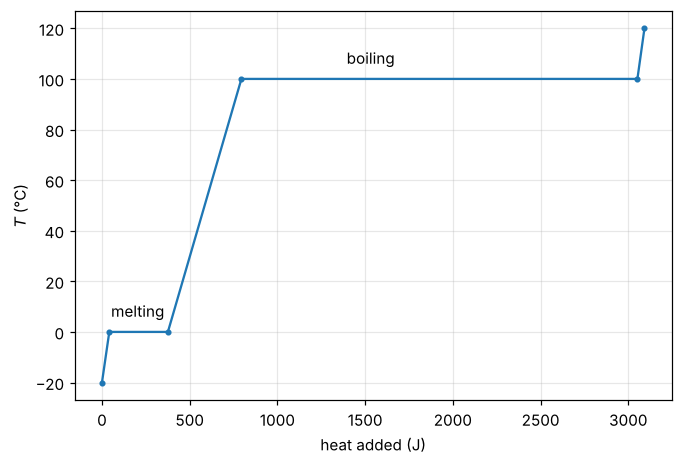

In [4]:
#| label: fig-ice-to-steam
#| caption: "Temperature of 1 g of H₂O versus heat added at 1 atm, starting as ice at −20 °C. Flat steps are the latent heats (334 J to melt, 2257 J to boil); the sloped parts have slope 1/C (ice 2.1, water 4.19, steam 2.0 J/(g·K)). Boiling dominates the budget."
segs = [(-20, 0, 2.09), ("melt", 334), (0, 100, 4.19), ("boil", 2257), (100, 120, 2.01)]
Q = [0.0]; T = [-20.0]
for s in segs:
    if s[0] in ("melt", "boil"):
        Q.append(Q[-1] + s[1]); T.append(T[-1])
    else:
        Q.append(Q[-1] + s[2] * (s[1] - s[0])); T.append(s[1])
fig, ax = plt.subplots()
ax.plot(Q, T, "-o", ms=3)
ax.text(Q[1] + 10, 6, "melting"); ax.text(Q[3] + 600, 106, "boiling")
ax.set_xlabel("heat added (J)"); ax.set_ylabel("$T$ (°C)"); plt.show()

## Looking Ahead to Level 3

In Pathria, $U$, $H$ and the free energies of thermo topic 5 are not separate definitions: all of them come out of one function, the logarithm of a partition function. For example $U = -\partial\ln Z/\partial\beta$ and $F = -kT\ln Z$, and the Legendre transforms of T-M3 appear as changes of ensemble. The Level 2 skill this chapter builds, choosing the state function whose change equals the heat for your process, is what makes that machinery readable.

## Exercises

### Exercises

1. One mole of air ($\gamma = 1.4$) at 300 K and 1 atm is compressed adiabatically to 1/10 of its volume. Find the final pressure and temperature and the work done on the gas.
2. Show that for an ideal gas $C_P/C_V = (f+2)/f$, and look up $\gamma$ for helium and for CO₂. What do the values tell you about each molecule?
3. A bicycle pump is compressed quickly. Explain, using the first law, why its barrel gets warm. Is the warming caused by friction?
4. Show that the work done in an adiabatic process is $W = (P_fV_f - P_iV_i)/(\gamma - 1)$.
5. Use $dH = dU + P\,dV + V\,dP$ and the first law to show $\Delta H = Q$ for a quasistatic constant-pressure process.

:::{dropdown} Hints
1. $PV^\gamma$ and $TV^{\gamma-1}$ are constant; $W = \Delta U = C_V\Delta T$.
2. $C_V = \tfrac f2Nk$ and {eq}`eq-mayer`. CO₂ is linear; at room temperature some of its bending vibrations are partly active.
3. What happens to $U$ when $W > 0$ and $Q\approx 0$?
4. Integrate $-P\,dV$ with $P = KV^{-\gamma}$, or use $W = \Delta U = \tfrac{f}{2}\Delta(PV)$.
5. With $dP = 0$, $dH = dU + P\,dV$; substitute $dU = \delta Q - P\,dV$.
:::

:::{dropdown} Answers
1. $P_f = 10^{1.4}$ atm $= 25.1$ atm; $T_f = 300\times10^{0.4} = 754$ K; $W = \tfrac52R(454) = 9.4$ kJ.
2. He: 1.67, so $f = 3$ (monatomic). CO₂: about 1.29, so $f\approx 6.8$: 3 translations, 2 rotations, and partly excited vibrations.
3. $\Delta U = W > 0$: the work goes into internal energy and $T$ rises. Friction adds a little, but the main effect is adiabatic compression.
4. $W = \Delta U = \tfrac f2Nk\Delta T = \tfrac{1}{\gamma - 1}\Delta(PV)$.
5. $dH = \delta Q$ at constant $P$, so $\Delta H = Q$.
:::

## Summary

- $\Delta U = Q + W$; $U$ is a state function, $Q$ and $W$ belong to processes. Quasistatic compression work is $-\int P\,dV$.
- Ideal gas: isothermal $Q = -W = NkT\ln(V_f/V_i)$; adiabatic $PV^\gamma$ = const with $\gamma = (f+2)/f$.
- $C_V = (\partial U/\partial T)_V$, $C_P = (\partial H/\partial T)_P$, $C_P - C_V = Nk$ for an ideal gas. Phase changes absorb latent heat at fixed $T$.
- Enthalpy $H = U + PV$ is the heat absorbed at constant pressure.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.